In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Load both leagues
df_d1 = pd.read_csv("Bundesliga1_Cleaned.csv")
df_d2 = pd.read_csv("Bundesliga2_Cleaned.csv")

# Add H2H index if missing
for df in [df_d1, df_d2]:
    df["H2H_Index"] = (
        df["H2H_HomeWins"] - df["H2H_AwayWins"]
    )

# Columns unavailable before kickoff
exclude = [
    "FTR", "FTHG", "FTAG",
    "HTHG", "HTAG", "HTR",
    "HS", "AS", "HST", "AST",
    "HC", "AC", "HF", "AF",
    "HY", "AY", "HR", "AR",
    "HomePoints", "AwayPoints",
    "HomeTeam", "AwayTeam",
    "Date", "Season", "Division",
    "Matchday"
]

# Select only home-team features
features=['Home_Prev5SeasonAvgPPG', 'Away_Last5AvgRedCardsAgainst', 'Home_Last5AvgRedCardsAgainst', 'Home_Prev5SeasonAvgPoints', 'Away_Last5AvgGoalsFor', 'Home_Last5AvgShotsFor', 'Home_Last5Points', 'Away_Last5AvgFoulsAgainst', 'Home_Last5AvgShotsOnTargetFor', 'Away_Last5AvgShotsFor', 'Away_Last5AvgShotsOnTargetFor', 'Home_Last5AvgGoalsFor', 'Home_Last5AvgCornersFor', 'H2H_Index']# Include H2H Index (from home team's perspective)
features.append("H2H_Index")

print("Number of features:", len(features))
print(features)
print("Number of features:", len(features))
print(features)

Number of features: 15
['Home_Prev5SeasonAvgPPG', 'Away_Last5AvgRedCardsAgainst', 'Home_Last5AvgRedCardsAgainst', 'Home_Prev5SeasonAvgPoints', 'Away_Last5AvgGoalsFor', 'Home_Last5AvgShotsFor', 'Home_Last5Points', 'Away_Last5AvgFoulsAgainst', 'Home_Last5AvgShotsOnTargetFor', 'Away_Last5AvgShotsFor', 'Away_Last5AvgShotsOnTargetFor', 'Home_Last5AvgGoalsFor', 'Home_Last5AvgCornersFor', 'H2H_Index', 'H2H_Index']
Number of features: 15
['Home_Prev5SeasonAvgPPG', 'Away_Last5AvgRedCardsAgainst', 'Home_Last5AvgRedCardsAgainst', 'Home_Prev5SeasonAvgPoints', 'Away_Last5AvgGoalsFor', 'Home_Last5AvgShotsFor', 'Home_Last5Points', 'Away_Last5AvgFoulsAgainst', 'Home_Last5AvgShotsOnTargetFor', 'Away_Last5AvgShotsFor', 'Away_Last5AvgShotsOnTargetFor', 'Home_Last5AvgGoalsFor', 'Home_Last5AvgCornersFor', 'H2H_Index', 'H2H_Index']



===== Bundesliga 1 =====
Draw Weight: 1
Accuracy: 0.5096
Macro F1: 0.3849

Classification Report:
              precision    recall  f1-score   support

    Home Win       0.53      0.78      0.63       915
        Draw       0.19      0.01      0.02       512
    Away Win       0.49      0.52      0.50       661

    accuracy                           0.51      2088
   macro avg       0.40      0.44      0.38      2088
weighted avg       0.43      0.51      0.44      2088



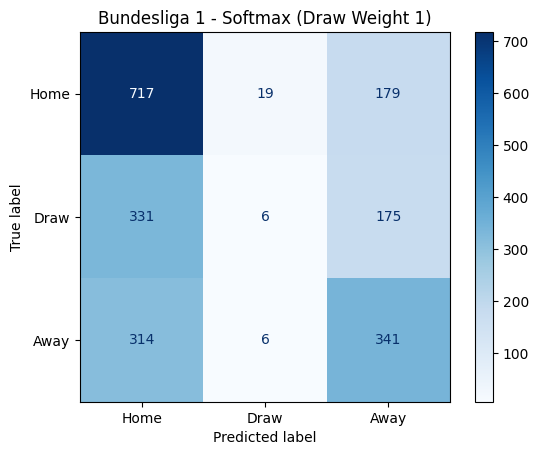


===== Bundesliga 2 =====
Draw Weight: 1
Accuracy: 0.4598
Macro F1: 0.3476

Classification Report:
              precision    recall  f1-score   support

    Home Win       0.47      0.82      0.60       903
        Draw       0.47      0.05      0.09       553
    Away Win       0.43      0.30      0.35       632

    accuracy                           0.46      2088
   macro avg       0.46      0.39      0.35      2088
weighted avg       0.46      0.46      0.39      2088



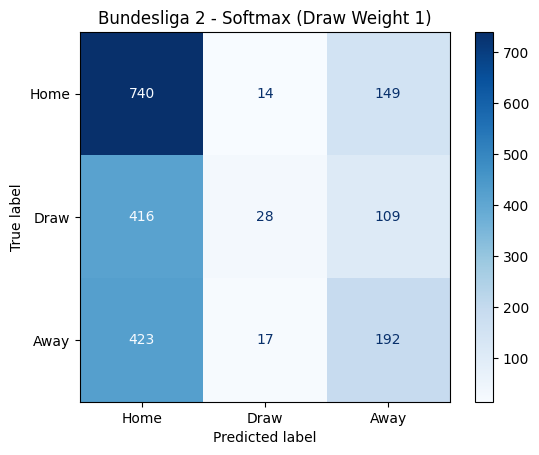

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

def run_softmax_weighted(df, features, league_name, draw_weight):

    X = df[features]
    y = df["FTR"]

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            solver="lbfgs",
            max_iter=2000,
            C=1.0
        ))
    ])

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # Get cross-validated probabilities
    probabilities = cross_val_predict(
        pipeline,
        X,
        y,
        cv=cv,
        method="predict_proba"
    )

    # Classes ordered A, D, H
    classes = np.array(["A", "D", "H"])

    # Increase draw score
    adjusted = probabilities.copy()
    adjusted[:, 1] *= draw_weight

    # Final predictions
    predictions = classes[np.argmax(adjusted, axis=1)]

    print(f"\n===== {league_name} =====")
    print(f"Draw Weight: {draw_weight}")
    print(f"Accuracy: {accuracy_score(y, predictions):.4f}")
    print(f"Macro F1: {f1_score(y, predictions, average='macro'):.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y, predictions,
        labels=["H", "D", "A"],
        target_names=["Home Win", "Draw", "Away Win"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y,
        predictions,
        labels=["H", "D", "A"],
        display_labels=["Home", "Draw", "Away"],
        cmap="Blues"
    )

    plt.title(f"{league_name} - Softmax (Draw Weight {draw_weight})")
    plt.show()


,League,Accuracy,Macro F1
0,Bundesliga 1,0.515326,0.394906
1,Bundesliga 2,0.440134,0.334387


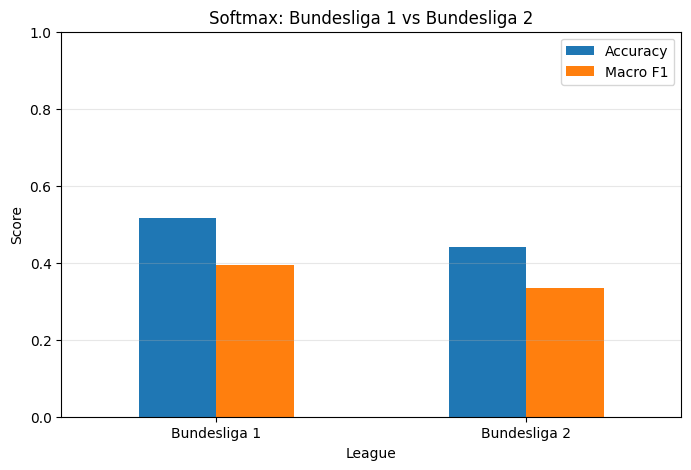

In [12]:
comparison = pd.DataFrame(results)

display(comparison)

comparison.set_index("League")[
    ["Accuracy", "Macro F1"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Softmax: Bundesliga 1 vs Bundesliga 2")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()


===== Bundesliga 1 Feature Importance =====


,Feature,Importance
1,HTHG,0.612487
0,HTAG,0.508903
11,Away_Last5AvgShotsFor,0.138075
14,Home_Last5AvgCornersFor,0.107357
8,Home_Last5Points,0.093208
10,Home_Last5AvgShotsOnTargetFor,0.075200
6,Away_Last5AvgGoalsFor,0.064769
13,Home_Last5AvgGoalsFor,0.064748
4,Home_Last5AvgRedCardsAgainst,0.055937
9,Away_Last5AvgFoulsAgainst,0.050444


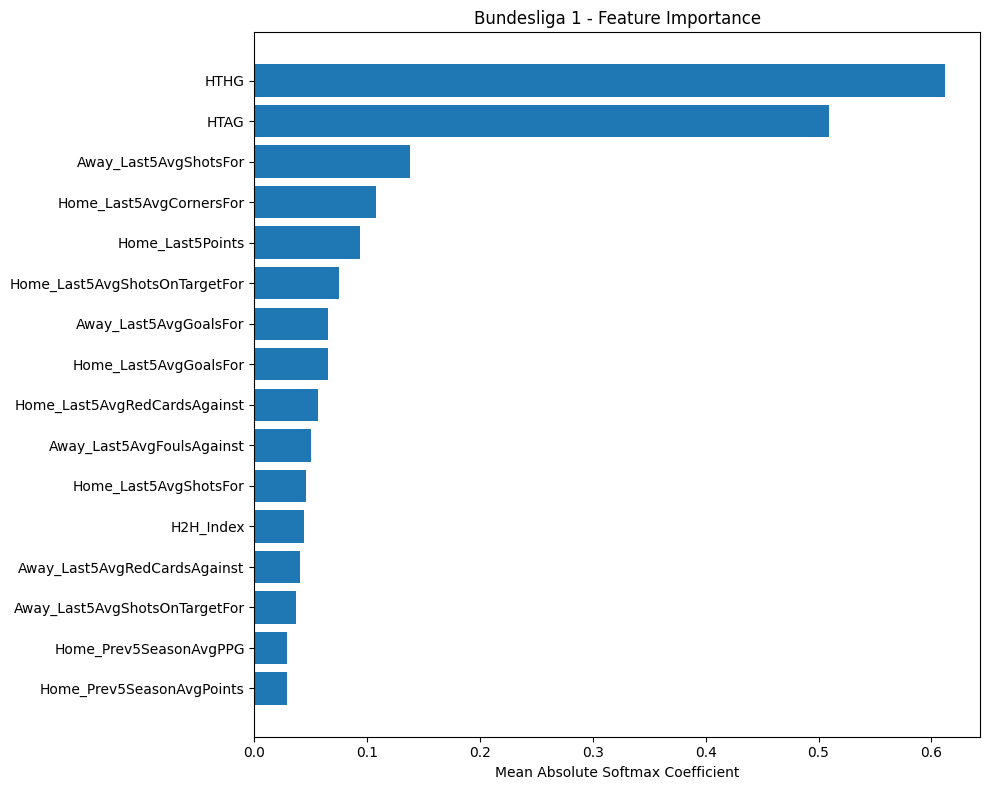


===== Bundesliga 2 Feature Importance =====


,Feature,Importance
0,HTAG,0.513808
1,HTHG,0.468398
7,Home_Last5AvgShotsFor,0.099820
12,Away_Last5AvgShotsOnTargetFor,0.071183
9,Away_Last5AvgFoulsAgainst,0.059052
13,Home_Last5AvgGoalsFor,0.057064
8,Home_Last5Points,0.055714
6,Away_Last5AvgGoalsFor,0.052344
5,Home_Prev5SeasonAvgPoints,0.038099
2,Home_Prev5SeasonAvgPPG,0.038099


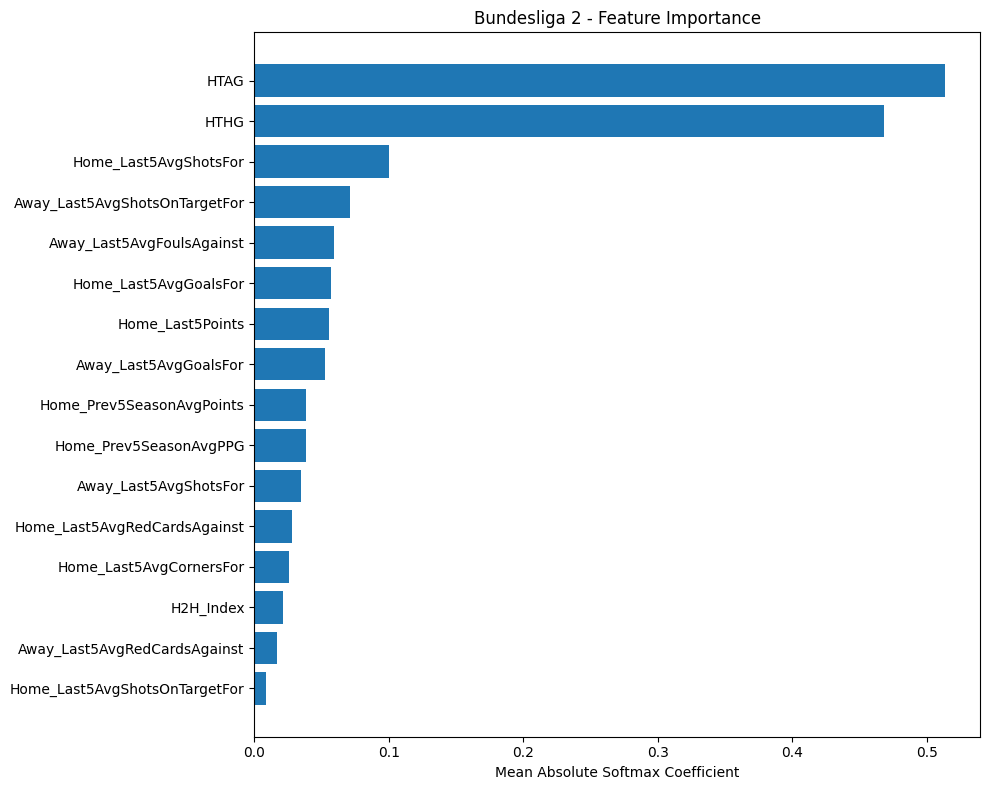

In [38]:
# ============================================
# SOFTMAX FEATURE IMPORTANCE
# ============================================

def softmax_feature_importance(df, league_name, features):

    X = df[features]
    y = df["FTR"]

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            solver="lbfgs",
            max_iter=2000,
            C=1.0
        ))
    ])

    # Fit model on dataset
    pipeline.fit(X, y)

    model = pipeline.named_steps["model"]

    # Coefficients for each outcome
    coefficients = model.coef_

    # Average absolute coefficient across classes
    importance = np.mean(
        np.abs(coefficients), axis=0
    )

    importance_df = pd.DataFrame({
        "Feature": features,
        "Importance": importance
    }).sort_values(
        "Importance", ascending=False
    )

    print(f"\n===== {league_name} Feature Importance =====")

    display(importance_df)

    plt.figure(figsize=(10, 8))
    plt.barh(
        importance_df["Feature"],
        importance_df["Importance"]
    )
    plt.gca().invert_yaxis()
    plt.xlabel("Mean Absolute Softmax Coefficient")
    plt.title(f"{league_name} - Feature Importance")
    plt.tight_layout()
    plt.show()

    return importance_df


importance_d1 = softmax_feature_importance(
    df_d1, "Bundesliga 1", features
)

importance_d2 = softmax_feature_importance(
    df_d2, "Bundesliga 2", features
)

In [14]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def find_best_features(df, features, league_name):

    X = df[features]
    y = df["FTR"]

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("softmax", LogisticRegression(
            solver="lbfgs",
            max_iter=2000
        ))
    ])

    selected = []
    remaining = features.copy()
    results = []

    while remaining:

        scores = []

        for feature in remaining:

            subset = selected + [feature]

            score = cross_val_score(
                model,
                X[subset],
                y,
                cv=cv,
                scoring="f1_macro",
                n_jobs=-1
            ).mean()

            scores.append((feature, score))

        best_feature, best_score = max(
            scores, key=lambda x: x[1]
        )

        selected.append(best_feature)
        remaining.remove(best_feature)

        results.append({
            "NumFeatures": len(selected),
            "AddedFeature": best_feature,
            "MacroF1": best_score,
            "Features": selected.copy()
        })

        print(
            f"{league_name} | "
            f"{len(selected)} features | "
            f"Added: {best_feature} | "
            f"F1: {best_score:.4f}"
        )

    results_df = pd.DataFrame(results)

    best_row = results_df.loc[
        results_df["MacroF1"].idxmax()
    ]

    print(f"\n===== {league_name} BEST SUBSET =====")
    print("Number of features:", best_row["NumFeatures"])
    print("Macro F1:", round(best_row["MacroF1"], 4))
    print("Features:", best_row["Features"])

    plt.figure(figsize=(9, 5))
    plt.plot(
        results_df["NumFeatures"],
        results_df["MacroF1"],
        marker="o"
    )
    plt.xlabel("Number of Features")
    plt.ylabel("5-Fold Macro F1")
    plt.title(f"{league_name} - Forward Feature Selection")
    plt.grid(alpha=0.3)
    plt.show()

    return results_df, best_row["Features"]

Bundesliga 1 | 1 features | Added: HTAG | F1: 0.4218
Bundesliga 1 | 2 features | Added: HTHG | F1: 0.4525
Bundesliga 1 | 3 features | Added: Home_Prev5SeasonAvgPPG | F1: 0.5244
Bundesliga 1 | 4 features | Added: Away_Last5AvgRedCardsAgainst | F1: 0.5328
Bundesliga 1 | 5 features | Added: Home_Last5AvgRedCardsAgainst | F1: 0.5390
Bundesliga 1 | 6 features | Added: Home_Prev5SeasonAvgPoints | F1: 0.5390
Bundesliga 1 | 7 features | Added: Away_Last5AvgGoalsFor | F1: 0.5368
Bundesliga 1 | 8 features | Added: Home_Last5AvgShotsFor | F1: 0.5376
Bundesliga 1 | 9 features | Added: Home_Last5Points | F1: 0.5422
Bundesliga 1 | 10 features | Added: Away_Last5AvgFoulsAgainst | F1: 0.5451
Bundesliga 1 | 11 features | Added: Home_Last5AvgShotsOnTargetFor | F1: 0.5449
Bundesliga 1 | 12 features | Added: Away_Last5AvgShotsFor | F1: 0.5455
Bundesliga 1 | 13 features | Added: Away_Last5AvgShotsOnTargetFor | F1: 0.5436
Bundesliga 1 | 14 features | Added: Home_Last5AvgGoalsFor | F1: 0.5454
Bundesliga 1 | 

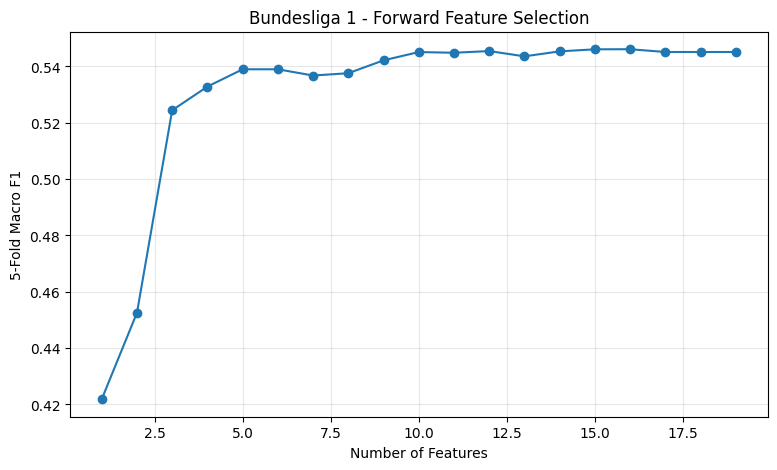

Bundesliga 2 | 1 features | Added: HTAG | F1: 0.4127
Bundesliga 2 | 2 features | Added: HTHG | F1: 0.4385
Bundesliga 2 | 3 features | Added: Home_Prev5SeasonAvgPPG | F1: 0.4892
Bundesliga 2 | 4 features | Added: H2H_Index | F1: 0.5055
Bundesliga 2 | 5 features | Added: Home_Prev5SeasonAvgPoints | F1: 0.5055
Bundesliga 2 | 6 features | Added: H2H_Index | F1: 0.5055
Bundesliga 2 | 7 features | Added: H2H_Index | F1: 0.5055
Bundesliga 2 | 8 features | Added: H2H_Index | F1: 0.5055
Bundesliga 2 | 9 features | Added: Home_Last5Points | F1: 0.5039
Bundesliga 2 | 10 features | Added: Home_Last5AvgGoalsFor | F1: 0.5131
Bundesliga 2 | 11 features | Added: Away_Last5AvgShotsFor | F1: 0.5147
Bundesliga 2 | 12 features | Added: Away_Last5AvgShotsOnTargetFor | F1: 0.5156
Bundesliga 2 | 13 features | Added: Away_Last5AvgGoalsFor | F1: 0.5141
Bundesliga 2 | 14 features | Added: Away_Last5AvgRedCardsAgainst | F1: 0.5132
Bundesliga 2 | 15 features | Added: Away_Last5AvgFoulsAgainst | F1: 0.5113
Bundesl

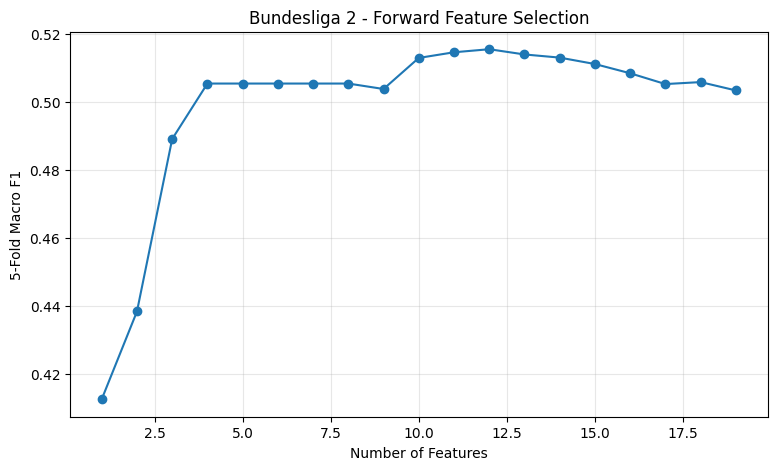


Best D1 features:
['HTAG', 'HTHG', 'Home_Prev5SeasonAvgPPG', 'Away_Last5AvgRedCardsAgainst', 'Home_Last5AvgRedCardsAgainst', 'Home_Prev5SeasonAvgPoints', 'Away_Last5AvgGoalsFor', 'Home_Last5AvgShotsFor', 'Home_Last5Points', 'Away_Last5AvgFoulsAgainst', 'Home_Last5AvgShotsOnTargetFor', 'Away_Last5AvgShotsFor', 'Away_Last5AvgShotsOnTargetFor', 'Home_Last5AvgGoalsFor', 'Home_Last5AvgCornersFor', 'H2H_Index']

Best D2 features:
['HTAG', 'HTHG', 'Home_Prev5SeasonAvgPPG', 'H2H_Index', 'Home_Prev5SeasonAvgPoints', 'H2H_Index', 'H2H_Index', 'H2H_Index', 'Home_Last5Points', 'Home_Last5AvgGoalsFor', 'Away_Last5AvgShotsFor', 'Away_Last5AvgShotsOnTargetFor']


In [34]:
results_d1, best_features_d1 = find_best_features(
    df_d1, features, "Bundesliga 1"
)

results_d2, best_features_d2 = find_best_features(
    df_d2, features, "Bundesliga 2"
)

print("\nBest D1 features:")
print(best_features_d1)

print("\nBest D2 features:")
print(best_features_d2)

In [20]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score,
    recall_score
)

def test_draw_weights(df, features):

    X = df[features]
    y = df["FTR"]

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            solver="lbfgs",
            max_iter=2000
        ))
    ])

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # Out-of-fold probabilities
    probabilities = cross_val_predict(
        pipeline,
        X,
        y,
        cv=cv,
        method="predict_proba"
    )

    # sklearn sorts classes alphabetically: A, D, H
    classes = np.array(["A", "D", "H"])

    results = []

    for weight in np.arange(1.0, 2.6, 0.1):

        adjusted = probabilities.copy()

        # Increase draw score
        adjusted[:, 1] *= weight

        predictions = classes[
            np.argmax(adjusted, axis=1)
        ]

        results.append({
            "DrawWeight": round(weight, 2),
            "Accuracy": accuracy_score(y, predictions),
            "MacroF1": f1_score(
                y, predictions, average="macro"
            ),
            "DrawRecall": recall_score(
                y, predictions,
                labels=["D"],
                average="macro",
                zero_division=0
            )
        })

    return pd.DataFrame(results)


draw_results_d1 = test_draw_weights(
    df_d1, features
)

draw_results_d2 = test_draw_weights(
    df_d2, features
)

display(draw_results_d1)
display(draw_results_d2)

,DrawWeight,Accuracy,MacroF1,DrawRecall
0,1.0,0.509579,0.384942,0.011719
1,1.1,0.511494,0.399691,0.037109
2,1.2,0.507184,0.411440,0.068359
3,1.3,0.503352,0.428616,0.121094
4,1.4,0.496648,0.439809,0.179688
5,1.5,0.492816,0.451570,0.251953
6,1.6,0.479885,0.450992,0.326172
7,1.7,0.472222,0.451300,0.388672
8,1.8,0.461207,0.446591,0.472656
9,1.9,0.447797,0.438493,0.542969


,DrawWeight,Accuracy,MacroF1,DrawRecall
0,1.0,0.459291,0.347327,0.050633
1,1.1,0.444444,0.344034,0.068716
2,1.2,0.438697,0.356124,0.117541
3,1.3,0.427682,0.359618,0.168174
4,1.4,0.415230,0.359707,0.231465
5,1.5,0.396552,0.353600,0.316456
6,1.6,0.383142,0.346342,0.403255
7,1.7,0.374521,0.338348,0.491863
8,1.8,0.366379,0.328739,0.594937
9,1.9,0.351054,0.311664,0.656420
